In [38]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
%matplotlib inline

In [39]:
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from matplotlib import pyplot

In [40]:
X,y=make_classification(n_samples=1000,n_classes=2,random_state=10)

In [41]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=10)


In [42]:
## created dummy model with zero as output
dummy_model_prob=[0 for _ in range(len(y_test))]
dummy_model_prob

[0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

In [43]:
model=LogisticRegression()
model.fit(X_train,y_train)

LogisticRegression()

In [44]:
## Prediction based on probability
model_prob=model.predict_proba(X_test)
# focus on the positive outcome
model_prob=model_prob[:,1]

In [45]:
model_prob

array([0.88700661, 0.9793287 , 0.26194882, 0.95581816, 0.28248095,
       0.01727562, 0.91136496, 0.27988864, 0.70830593, 0.64215053,
       0.0185857 , 0.74254014, 0.6185222 , 0.16090738, 0.31948847,
       0.00379897, 0.42240717, 0.64151965, 0.16355871, 0.99795352,
       0.7047473 , 0.55991365, 0.51604409, 0.80315093, 0.56273888,
       0.16848543, 0.07831389, 0.19079266, 0.02439888, 0.22513654,
       0.15175491, 0.92639069, 0.00255472, 0.15732946, 0.73084866,
       0.87193681, 0.29643616, 0.52384885, 0.89274516, 0.89936893,
       0.73080141, 0.23439312, 0.97299426, 0.12990822, 0.00543924,
       0.04612874, 0.28776372, 0.99734681, 0.9957382 , 0.06021269,
       0.14971126, 0.92508051, 0.82051241, 0.0040566 , 0.91256106,
       0.85620402, 0.71296494, 0.75332615, 0.71516104, 0.04868067,
       0.77891521, 0.12189378, 0.97936222, 0.98249496, 0.791712  ,
       0.29346436, 0.05556089, 0.10620962, 0.94157829, 0.0613907 ,
       0.01171882, 0.94861957, 0.00683713, 0.00369717, 0.19519

In [46]:
## calculate the ROC scores]
dummy_model_auc=roc_auc_score(y_test,dummy_model_prob)
model_auc=roc_auc_score(y_test,model_prob)
print(dummy_model_auc)
print(model_auc)

0.5
0.9332298136645962


In [47]:
## The ROC curve is drawn by calculating 
# the true positive rate (TPR) and false positive rate 
# (FPR) at every possible threshold 
# (in practice, at selected intervals), then graphing TPR over FPR

In [48]:
dummy_fpr,dummy_tpr,_=roc_curve(y_test,dummy_model_prob)
model_fpr,model_tpr,thresholds=roc_curve(y_test,model_prob)



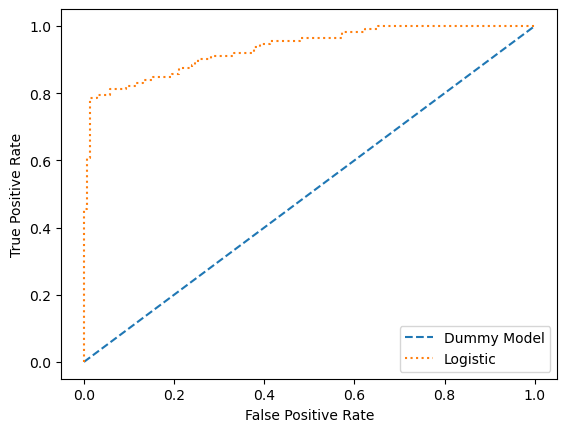

In [49]:
plt.plot(dummy_fpr,dummy_tpr,label='Dummy Model',linestyle='--')
plt.plot(model_fpr,model_tpr,label='Logistic',linestyle='dotted')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

 ### the AUC curve  in logistic model is greater then the   AUC (Are under the curve) in dummy model

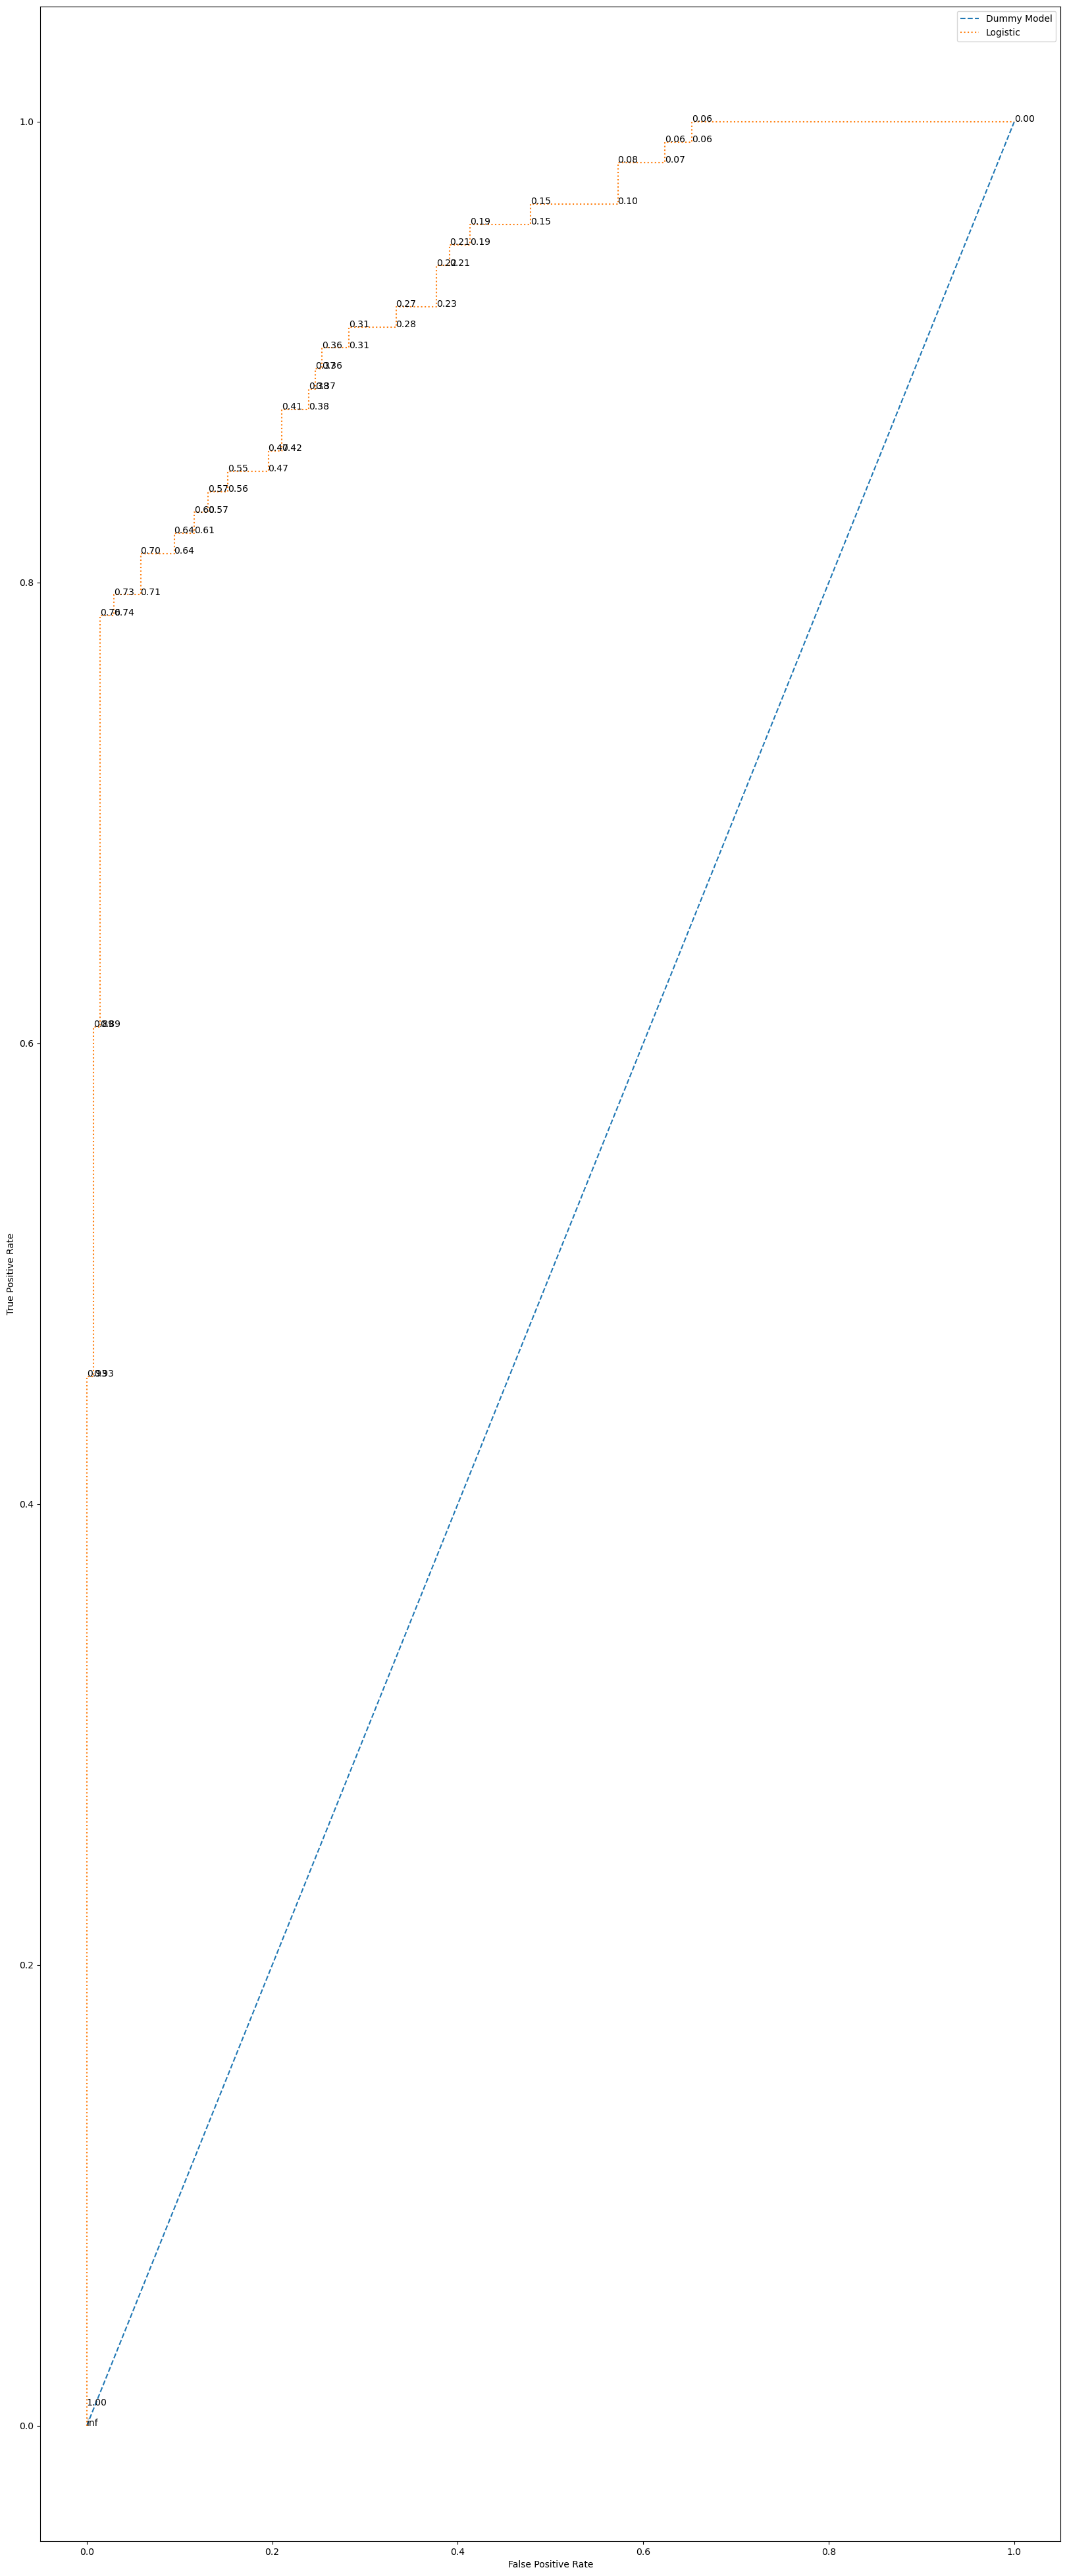

In [ ]:
fig, ax = plt.subplots(figsize=(20,50))

ax.plot(dummy_fpr, dummy_tpr, label='Dummy Model', linestyle='--')
ax.plot(model_fpr, model_tpr, label='Logistic', linestyle='dotted')

for fpr, tpr, thr in zip(model_fpr, model_tpr, thresholds):
    ax.annotate(f'{thr:.2f}', xy=(fpr, tpr))

ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend()
plt.show()